In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
print(data.shape)

(7043, 21)


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
data['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

Classes are Imbalanced

In [13]:
data.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
#Total Charges is in string format, we need to convert it to numeric.
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print(data['TotalCharges'].isnull().sum())

11


In [15]:
#the data that has missing values in TotalCharges column
data[data['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Here we can see that the tenure is 0 for all the customer , who has total charge as null. This shows that all are new customers

In [16]:
data['TotalCharges'] = data['TotalCharges'].fillna(0)
data['TotalCharges'].isna().sum()

np.int64(0)

In [ ]:
# Binary encoding for the target variable 'Churn'
data['ChurnFlag'] = (data['Churn'] == 'Yes').astype(int)
for col in ['Contract','InternetService', 'PaymentMethod', 'TechSupport', 'PaperlessBilling']:
    print(data.groupby(col)['ChurnFlag'].mean().sort_values(ascending=False).round(3), '\n')

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: ChurnFlag, dtype: float64 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: ChurnFlag, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: ChurnFlag, dtype: float64 

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: ChurnFlag, dtype: float64 

PaperlessBilling
Yes    0.336
No     0.163
Name: ChurnFlag, dtype: float64 



##### Churn rate by category
- Contract: month-to-month customers churn at 42.7%, one-year at 11.3%, and two-year at 2.8%. This is the  strongest signal.
- Internet service: fiber optic customers churn at 41.9%, against 19.0% for DSL and 7.4% for customers with no internet.
- Payment method: electronic check customers churn at 45.3%, while the other three methods sit between 15% and 19%.
- Tech support: customers without it churn at 41.6%, against 15.2% for those with it.
Paperless billing: customers on it churn at 33.6%, against 16.3% for those who aren’t.

In [22]:
data.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


#### Numeric features (medians)

- Tenure: churners have a median of 10 months, against 38 for stayers.
- Monthly charges: churners pay more, about $79.65 against $64.43.
- Total charges: churners have lower totals ($704 vs $1,680), which follows from their short tenure.

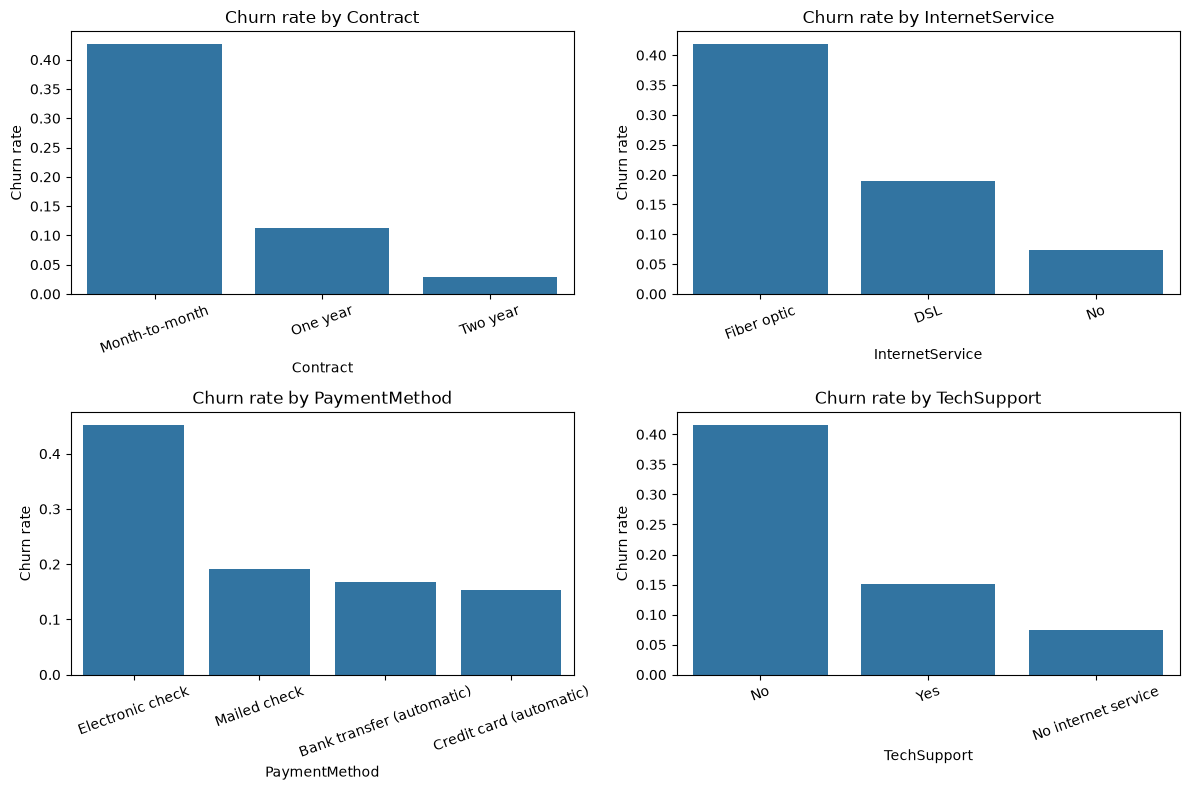

In [29]:
cols = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cols):
    rate = data.groupby(col)['ChurnFlag'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

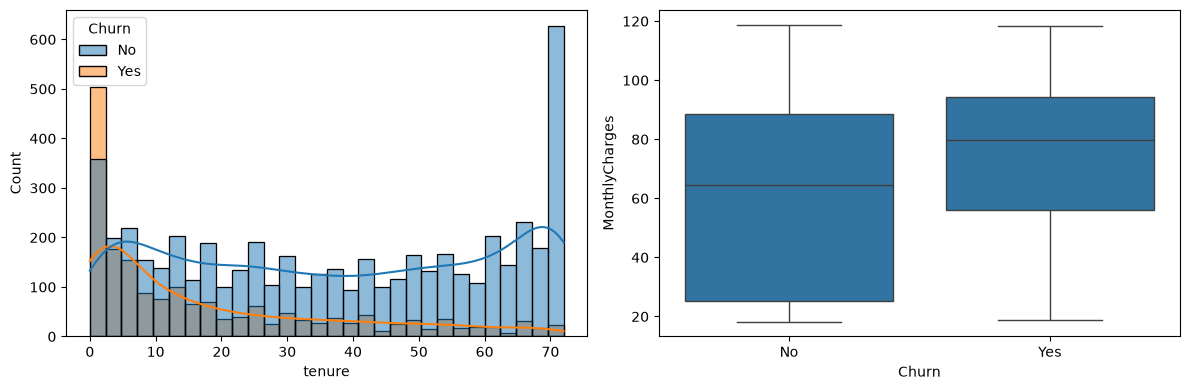

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x='tenure', hue='Churn', bins=30, kde=True, ax=axes[0])
sns.boxplot(data=data, x='Churn', y='MonthlyCharges', ax=axes[1])
plt.tight_layout()
plt.show()

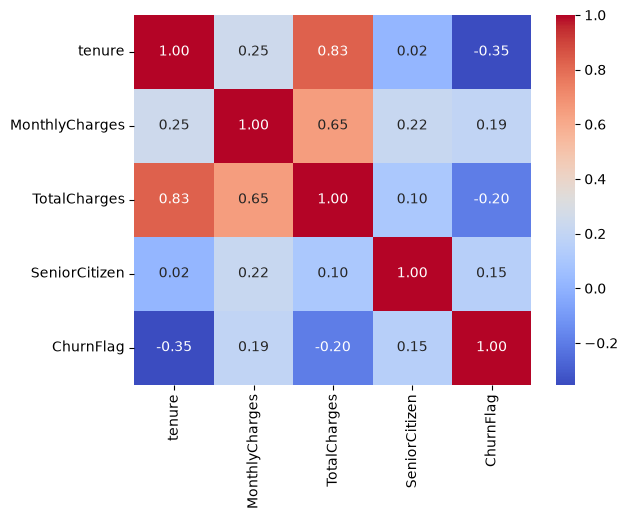

In [31]:
num = data[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']]
sns.heatmap(num.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

#### Correlation with churn

- Tenure: -0.35, the strongest numeric link, so longer-tenured customers are less likely to leave.
- Monthly charges: +0.19.
- Total charges: -0.20, mostly because it moves with tenure.
- Senior citizen: +0.15.

Overall picture: churn is concentrated among new customers on month-to-month contracts with fiber, paying by electronic check, with no tech support, and paying higher monthly bills.